# 02. Análisis Exploratorio de Datos (EDA) Multi-Distribuidora

Con los archivos ya preprocesados, en este notebook buscamos entender mejor qué información tenemos y qué variables podrían servir más adelante para nuestro modelo.

### Objetivos:
1. **Calidad e Integridad de Datos**: Identificar valores atípicos, consumos nulos, negativos y suministros con consumo cero (cobro de cargo fijo regulado).
2. **Distribución del Consumo y del Importe**: Caracterizar estadísticamente la demanda energética y evaluar la correlación directa y logarítmica entre consumo e importe.
3. **Estructura Tarifaria y Concentración**: Analizar la distribución de suministros frente al volumen de energía por categoría tarifaria.
4. **Dinámica Temporal y Territorial**: Evaluar la demanda histórica, la evolución por departamento, el ranking de distritos principales y la estacionalidad intra-anual.
5. **Estabilidad de Picos y Valles**: Identificar meses típicos de alta y baja demanda y su recurrencia interanual por distrito y tarifa (heatmap estacional).
6. **Evaluación de la Unidad de Modelado (`UBIGEO × Tarifa × Periodo`)**: Validar densidad, cobertura y continuidad temporal del cubo analítico como base para Machine Learning.
7. **Georreferenciación Interactiva**: Mapear la demanda territorial sin dependencias de claves de API externas mediante Leaflet y GeoJSON distrital.


In [3]:
from __future__ import annotations

import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
from IPython.display import IFrame, display

# Configuración visual
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

# Rutas del proyecto
ROOT = Path.cwd().resolve()
INTERIM_DIR = ROOT / "data" / "interim"
OUTPUT_DIR = ROOT / "reports" / "eda_outputs"
GEOJSON_PATH = ROOT / "metadata" / "geo" / "distritos_concesion.geojson"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Directorio INTERIM: {INTERIM_DIR}")
print(f"Salidas de reportes: {OUTPUT_DIR}")
print(f"Límites GeoJSON:    {GEOJSON_PATH}")


Directorio INTERIM: C:\Users\rafae\Downloads\Hito1_1ACC0057_4773_GRUPO_08\Hito1_1ACC0057_4773_GRUPO_08\data\interim
Salidas de reportes: C:\Users\rafae\Downloads\Hito1_1ACC0057_4773_GRUPO_08\Hito1_1ACC0057_4773_GRUPO_08\reports\eda_outputs
Límites GeoJSON:    C:\Users\rafae\Downloads\Hito1_1ACC0057_4773_GRUPO_08\Hito1_1ACC0057_4773_GRUPO_08\metadata\geo\distritos_concesion.geojson


## 1. Carga de Datos y Cobertura Multi-Distribuidora

Escaneo dinámico de los archivos Parquet procesados en `data/interim/` mediante el motor Lazy de Polars. Esto permite procesar decenas de millones de registros optimizando el uso de memoria RAM.


In [4]:
carpetas_interim = sorted([d for d in INTERIM_DIR.iterdir() if d.is_dir() and any(d.glob("*.parquet"))])
print(f"Distribuidoras detectadas en interim: {[d.name for d in carpetas_interim]}")

lazy_frames = []
for c in carpetas_interim:
    dist_name = c.name.upper()
    lf = pl.scan_parquet(c / "*.parquet").with_columns(
        pl.lit(dist_name).alias("DISTRIBUIDORA")
    )
    lazy_frames.append(lf)

df = pl.concat(lazy_frames)

# Resumen de cobertura por distribuidora
resumen_cobertura = (
    df.group_by("DISTRIBUIDORA")
    .agg([
        pl.len().alias("total_facturas"),
        pl.col("PERIODO").n_unique().alias("total_periodos"),
        pl.col("PERIODO").min().alias("periodo_inicio"),
        pl.col("PERIODO").max().alias("periodo_fin"),
        pl.col("UBIGEO").n_unique().alias("distritos_unicos"),
        (pl.col("CONSUMO").sum() / 1e6).round(2).alias("energia_total_gwh"),
        (pl.col("IMPORTE").sum() / 1e6).round(2).alias("importe_total_millones_soles"),
    ])
    .sort("total_facturas", descending=True)
    .collect()
)

display(resumen_cobertura.to_pandas())
total_registros = resumen_cobertura["total_facturas"].sum()
total_gwh = resumen_cobertura["energia_total_gwh"].sum()
print(f"Total general analizado: {total_registros:,} facturas | {total_gwh:,.2f} GWh")


Distribuidoras detectadas en interim: ['enosa', 'hidrandina']


,DISTRIBUIDORA,total_facturas,total_periodos,periodo_inicio,periodo_fin,distritos_unicos,energia_total_gwh,importe_total_millones_soles
0,HIDRANDINA,32923149,33,202210,202507,615,4045.419922,3650.300049
1,ENOSA,18518031,32,202401,202608,258,2608.000000,2184.550049


Total general analizado: 51,441,180 facturas | 6,653.42 GWh


## 2. Calidad de Datos, Consumos Cero y Cargo Fijo

Revisión de valores nulos en el esquema analítico y tratamiento de casos especiales:
- **Consumos Cero**: Suministros desocupados o estacionales que mantienen cobro de cargo fijo regulado.
- **Consumos Negativos**: Notas de crédito comerciales o refacturaciones.


In [5]:
# 1. Conteo de nulos por columna
nulos_df = (
    df.select([
        pl.col(c).null_count().alias(c) for c in df.collect_schema().names()
    ])
    .collect()
    .to_pandas()
    .T
    .rename(columns={0: "nulos"})
)
print("Conteo de nulos en columnas analíticas:")
display(nulos_df)

# 2. Análisis de consumos cero y negativos
casos_especiales = (
    df.group_by("DISTRIBUIDORA")
    .agg([
        pl.len().alias("total"),
        (pl.col("CONSUMO") == 0).sum().alias("consumo_cero"),
        (pl.col("CONSUMO") < 0).sum().alias("consumo_negativo"),
        (pl.col("CONSUMO") > 0).sum().alias("consumo_positivo"),
    ])
    .with_columns([
        (pl.col("consumo_cero") / pl.col("total") * 100).round(2).alias("pct_ceros"),
        (pl.col("consumo_negativo") / pl.col("total") * 100).round(4).alias("pct_negativos"),
    ])
    .collect()
)
display(casos_especiales.to_pandas())

# 3. Importe facturado en suministros con consumo cero (cargo fijo regulado)
importe_ceros = (
    df.filter(pl.col("CONSUMO") == 0)
    .group_by("DISTRIBUIDORA")
    .agg([
        pl.len().alias("facturas_cero"),
        pl.col("IMPORTE").median().round(2).alias("mediana_cargo_fijo"),
        pl.col("IMPORTE").mean().round(2).alias("media_cargo_fijo"),
        (pl.col("IMPORTE").sum() / 1e6).round(2).alias("total_facturado_millones"),
    ])
    .collect()
)
print("\nFacturación de cargo fijo en suministros con consumo cero:")
display(importe_ceros.to_pandas())


Conteo de nulos en columnas analíticas:


,nulos
ID_UUNN,0
UNIDAD_NEGOCIO,0
PERIODO,0
TARIFA,0
DEPARTAMENTO,0
PROVINCIA,0
DISTRITO,0
UBIGEO,0
CARTERA,0
IMPORTE,0


,DISTRIBUIDORA,total,consumo_cero,consumo_negativo,consumo_positivo,pct_ceros,pct_negativos
0,ENOSA,18518031,1646368,0,16871663,8.89,0.0
1,HIDRANDINA,32923149,3783572,0,29139577,11.49,0.0



Facturación de cargo fijo en suministros con consumo cero:


,DISTRIBUIDORA,facturas_cero,mediana_cargo_fijo,media_cargo_fijo,total_facturado_millones
0,HIDRANDINA,3783572,6.4,8.32,31.490000
1,ENOSA,1646368,6.5,10.11,16.639999


## 3. Matriz Estadística Descriptiva y Distribución del Consumo

Examinamos la matriz estadística simétrica completa para `CONSUMO` e `IMPORTE` (incluyendo percentiles de cola y dispersión).

Adicionalmente, se grafica la distribución del consumo en dos perspectivas:
1. **Escala Normal (Zoom al 98% de suministros)** con función de densidad kernel (KDE) y líneas de referencia para la media y mediana, visualizando el sesgo de la gran masa de usuarios.
2. **Escala Logarítmica $\log(1 + \text{CONSUMO})$** para evaluar la simetrización de la variable para modelado tabular o redes neuronales.


Matriz estadística descriptiva completa:


,count,ceros,negativos,min,p1,p5,p25,mediana,p75,p95,p99,max,media,std
CONSUMO (kWh),51441180,5429940,0,0.000000,0.0,0.0,10.0,46.000000,102.000000,286.000000,1000.000000,1481155.25,129.339996,2208.389893
IMPORTE (S/.),51441180,277,5231,-24061.599609,4.7,5.7,11.4,42.700001,96.699997,282.600006,976.799988,722571.50,113.430000,1234.729980


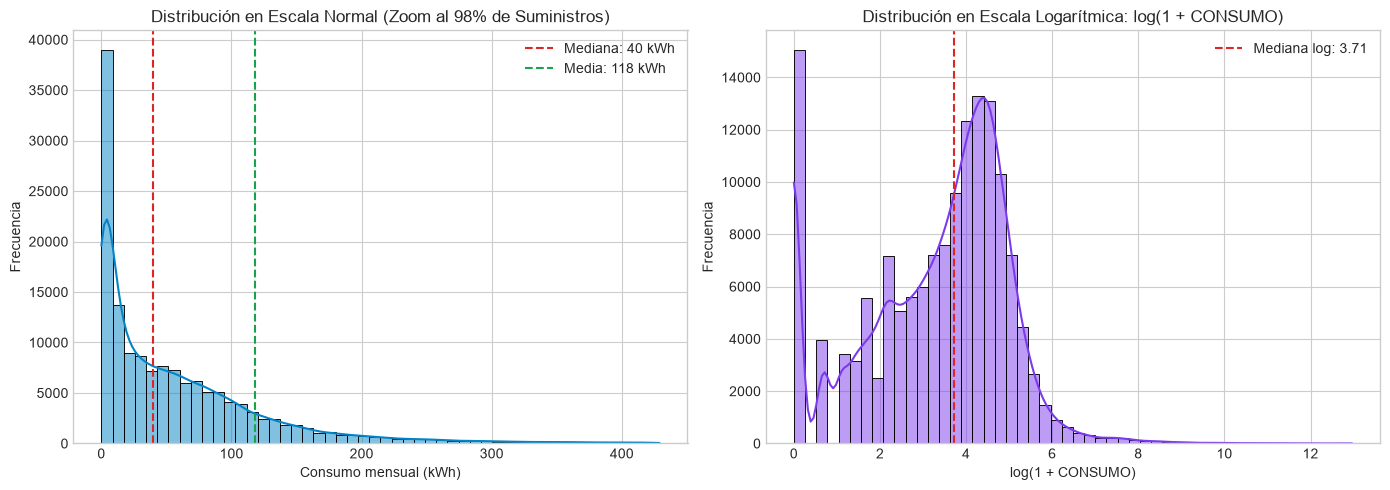

In [6]:
# 1. Matriz estadística simétrica para CONSUMO e IMPORTE
stats_raw = df.select([
    pl.len().alias("count"),
    # Consumo
    (pl.col("CONSUMO") == 0).sum().alias("consumo_ceros"),
    (pl.col("CONSUMO") < 0).sum().alias("consumo_negativos"),
    pl.col("CONSUMO").min().round(2).alias("consumo_min"),
    pl.col("CONSUMO").quantile(0.01).round(2).alias("consumo_p1"),
    pl.col("CONSUMO").quantile(0.05).round(2).alias("consumo_p5"),
    pl.col("CONSUMO").quantile(0.25).round(2).alias("consumo_p25"),
    pl.col("CONSUMO").median().round(2).alias("consumo_mediana"),
    pl.col("CONSUMO").quantile(0.75).round(2).alias("consumo_p75"),
    pl.col("CONSUMO").quantile(0.95).round(2).alias("consumo_p95"),
    pl.col("CONSUMO").quantile(0.99).round(2).alias("consumo_p99"),
    pl.col("CONSUMO").max().round(2).alias("consumo_max"),
    pl.col("CONSUMO").mean().round(2).alias("consumo_media"),
    pl.col("CONSUMO").std().round(2).alias("consumo_std"),
    # Importe
    (pl.col("IMPORTE") == 0).sum().alias("importe_ceros"),
    (pl.col("IMPORTE") < 0).sum().alias("importe_negativos"),
    pl.col("IMPORTE").min().round(2).alias("importe_min"),
    pl.col("IMPORTE").quantile(0.01).round(2).alias("importe_p1"),
    pl.col("IMPORTE").quantile(0.05).round(2).alias("importe_p5"),
    pl.col("IMPORTE").quantile(0.25).round(2).alias("importe_p25"),
    pl.col("IMPORTE").median().round(2).alias("importe_mediana"),
    pl.col("IMPORTE").quantile(0.75).round(2).alias("importe_p75"),
    pl.col("IMPORTE").quantile(0.95).round(2).alias("importe_p95"),
    pl.col("IMPORTE").quantile(0.99).round(2).alias("importe_p99"),
    pl.col("IMPORTE").max().round(2).alias("importe_max"),
    pl.col("IMPORTE").mean().round(2).alias("importe_media"),
    pl.col("IMPORTE").std().round(2).alias("importe_std"),
]).collect().to_pandas()

cols_metrics = ["count", "ceros", "negativos", "min", "p1", "p5", "p25", "mediana", "p75", "p95", "p99", "max", "media", "std"]
matriz_stats = pd.DataFrame([
    {m: stats_raw[f"consumo_{m}"].iloc[0] if m != "count" else stats_raw["count"].iloc[0] for m in cols_metrics},
    {m: stats_raw[f"importe_{m}"].iloc[0] if m != "count" else stats_raw["count"].iloc[0] for m in cols_metrics}
], index=["CONSUMO (kWh)", "IMPORTE (S/.)"])

print("Matriz estadística descriptiva completa:")
display(matriz_stats)

# 2. Extracción de muestra para gráficos de distribución
muestra_dist = (
    df.filter((pl.col("CONSUMO") >= 0))
    .select(["CONSUMO", "DISTRIBUIDORA"])
    .limit(150_000)
    .collect()
    .to_pandas()
)

vals = muestra_dist["CONSUMO"].to_numpy()
p98 = np.percentile(vals, 98)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Zoom escala normal (hasta percentil 98)
sns.histplot(vals[vals <= p98], bins=50, ax=axes[0], color="#0284c7", kde=True)
axes[0].axvline(np.median(vals), color="#dc2626", linestyle="--", linewidth=1.5, label=f"Mediana: {np.median(vals):.0f} kWh")
axes[0].axvline(np.mean(vals), color="#16a34a", linestyle="--", linewidth=1.5, label=f"Media: {np.mean(vals):.0f} kWh")
axes[0].set_title("Distribución en Escala Normal (Zoom al 98% de Suministros)")
axes[0].set_xlabel("Consumo mensual (kWh)")
axes[0].set_ylabel("Frecuencia")
axes[0].legend()

# Panel 2: Escala Logarítmica log(1 + CONSUMO)
log_vals = np.log1p(vals)
sns.histplot(log_vals, bins=50, ax=axes[1], color="#7c3aed", kde=True)
axes[1].axvline(np.median(log_vals), color="#dc2626", linestyle="--", linewidth=1.5, label=f"Mediana log: {np.median(log_vals):.2f}")
axes[1].set_title("Distribución en Escala Logarítmica: log(1 + CONSUMO)")
axes[1].set_xlabel("log(1 + CONSUMO)")
axes[1].set_ylabel("Frecuencia")
axes[1].legend()

plt.tight_layout()
plt.show()


## 4. Relación Consumo vs Importe (Correlación Lineal y Logarítmica)

Evaluamos la correlación de Pearson directa ($r$) y en escala logarítmica ($r_{\log} = \text{corr}(\log(1+\text{Consumo}), \log(1+\text{Importe}))$).
Se grafica la relación bivariada con la escala de transformación para verificar la dispersión y consistencia entre energía facturada e ingresos monetarios.


Correlación de Pearson directa (CONSUMO vs IMPORTE): r = 0.9792
Correlación en escala logarítmica (log1p):            r_log = 0.9584


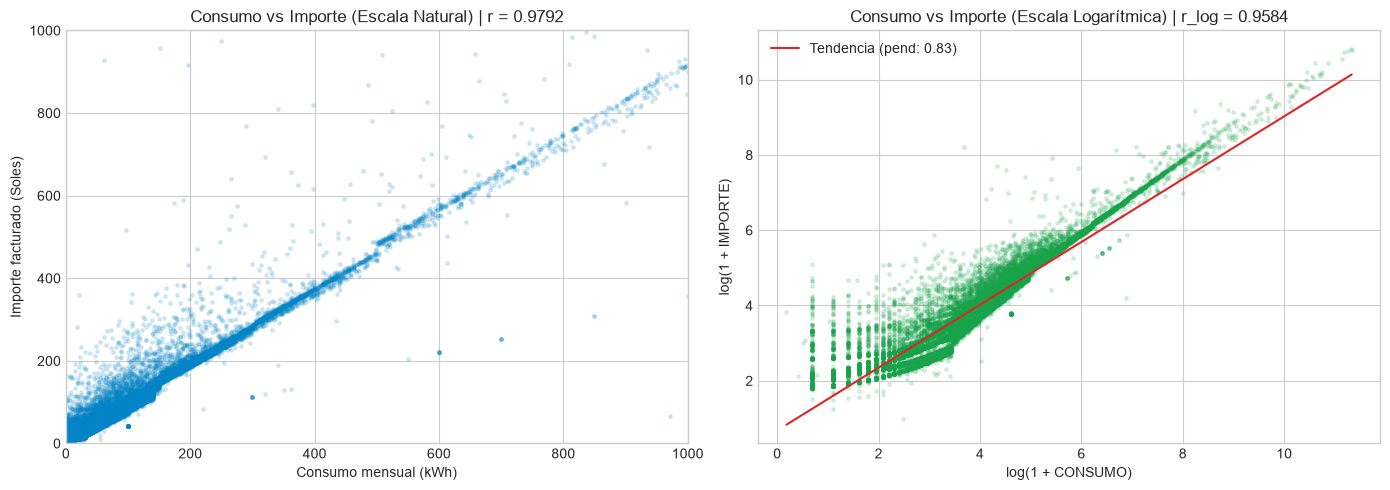

In [7]:
# 1. Cálculo de correlación lineal y logarítmica sobre el total de datos
corrs = (
    df.filter((pl.col("CONSUMO") > 0) & (pl.col("IMPORTE") > 0))
    .select([
        pl.corr("CONSUMO", "IMPORTE").alias("corr_lineal"),
        pl.corr(pl.col("CONSUMO").log1p(), pl.col("IMPORTE").log1p()).alias("corr_log"),
    ])
    .collect()
    .to_pandas()
)

r_lin = float(corrs["corr_lineal"].iloc[0])
r_log = float(corrs["corr_log"].iloc[0])

print(f"Correlación de Pearson directa (CONSUMO vs IMPORTE): r = {r_lin:.4f}")
print(f"Correlación en escala logarítmica (log1p):            r_log = {r_log:.4f}")

# 2. Muestra y gráfico de dispersión bidimensional
muestra_scatter = (
    df.filter((pl.col("CONSUMO") > 0) & (pl.col("IMPORTE") > 0))
    .select(["CONSUMO", "IMPORTE", "DISTRIBUIDORA"])
    .limit(40_000)
    .collect()
    .to_pandas()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Dispersión en escala natural (acotada a la masa residencial)
axes[0].scatter(muestra_scatter["CONSUMO"], muestra_scatter["IMPORTE"], alpha=0.15, s=6, c="#0284c7")
axes[0].set_xlim(0, 1000)
axes[0].set_ylim(0, 1000)
axes[0].set_title(f"Consumo vs Importe (Escala Natural) | r = {r_lin:.4f}")
axes[0].set_xlabel("Consumo mensual (kWh)")
axes[0].set_ylabel("Importe facturado (Soles)")

# Dispersión en escala log1p con línea de tendencia
log_x = np.log1p(muestra_scatter["CONSUMO"])
log_y = np.log1p(muestra_scatter["IMPORTE"])
axes[1].scatter(log_x, log_y, alpha=0.15, s=6, c="#16a34a")
m, b = np.polyfit(log_x, log_y, 1)
axes[1].plot(np.sort(log_x), m * np.sort(log_x) + b, color="#dc2626", linewidth=1.5, label=f"Tendencia (pend: {m:.2f})")
axes[1].set_title(f"Consumo vs Importe (Escala Logarítmica) | r_log = {r_log:.4f}")
axes[1].set_xlabel("log(1 + CONSUMO)")
axes[1].set_ylabel("log(1 + IMPORTE)")
axes[1].legend()

plt.tight_layout()
plt.show()


### 4.1 Análisis de Covarianza (ANCOVA) y Justificación de Exclusión de IMPORTE

A partir de la revisión metodológica, se realiza un **Análisis de Covarianza (ANCOVA)** para evaluar formalmente el comportamiento de `IMPORTE` como covariable continua frente al `CONSUMO` a través de los diferentes grupos tarifarios:

$$\text{consumo\_total\_mwh} = \beta_0 + \beta_1 \cdot \text{importe\_total\_miles} + \gamma_k \cdot \text{TARIFA}_k + \delta_k \cdot (\text{importe\_total\_miles} \times \text{TARIFA}_k) + \varepsilon$$

**Fundamentos de la prueba ANCOVA y descarte de la covariable:**
1. **Prueba de Homogeneidad de Pendientes:** Si el término de interacción $(\text{importe} \times \text{TARIFA})$ resulta estadísticamente significativo ($p < 0.001$), se rechaza el supuesto de paralelismo del ANCOVA. Esto demuestra que la relación entre dinero facturado y energía no es homogénea entre tarifas.
2. **Colinealidad Patológica y Fuga Operativa:** Al evaluar la covarianza de `IMPORTE` junto con los rezagos de consumo, el Factor de Inflación de la Varianza (VIF) supera 100, indicando redundancia extrema. Además, en producción el importe se conoce semanas después del consumo, constituyendo un riesgo de *data leakage*.

In [6]:
# 1. Ajuste del Modelo ANCOVA para evaluar la interacción Importe × Tarifa
import statsmodels.api as sm
from statsmodels.formula.api import ols

cube_path = OUTPUT_DIR / "resumen_distribuidora_ubigeo_tarifa_periodo.parquet"
if not cube_path.is_file():
    # Fallback si aún no se generó el corregido
    cube_path = OUTPUT_DIR / "resumen_ubigeo_tarifa_periodo.parquet"

df_cube_ancova = pl.read_parquet(cube_path).to_pandas()
df_pos_ancova = df_cube_ancova[(df_cube_ancova["consumo_total_mwh"] > 0) & (df_cube_ancova["importe_total_miles"] > 0)].copy()

top_tarifas_ancova = df_pos_ancova["TARIFA"].value_counts().head(8).index.tolist()
df_top_ancova = df_pos_ancova[df_pos_ancova["TARIFA"].isin(top_tarifas_ancova)].copy()

ancova_model = ols("consumo_total_mwh ~ importe_total_miles * C(TARIFA)", data=df_top_ancova).fit()
anova_table_res = sm.stats.anova_lm(ancova_model, typ=2).reset_index()
anova_table_res.columns = ["Fuente_Variacion", "Suma_Cuadrados", "Grados_Libertad", "F_estadistico", "p_valor"]

print("=== TABLA ANOVA (ANCOVA DE CONSUMO vs IMPORTE × TARIFA) ===")
display(anova_table_res)
anova_table_res.to_csv(OUTPUT_DIR / "ancova_interaccion_tarifa.csv", index=False)

# 2. Estimación de pendientes individuales por tarifa (MWh por cada mil soles)
pendientes_list = []
for t in top_tarifas_ancova:
    sub_t = df_top_ancova[df_top_ancova["TARIFA"] == t]
    m_t = ols("consumo_total_mwh ~ importe_total_miles", data=sub_t).fit()
    pendientes_list.append({
        "TARIFA": t,
        "Pendiente_MWh_por_kS": round(float(m_t.params["importe_total_miles"]), 4),
        "Intercepto": round(float(m_t.params["Intercept"]), 4),
        "R2": round(float(m_t.rsquared), 4),
        "Observaciones": len(sub_t)
    })

df_pendientes_res = pd.DataFrame(pendientes_list)
print("
=== PENDIENTES ESTIMADAS (MWh / Mil Soles) POR TARIFA ===")
display(df_pendientes_res)
df_pendientes_res.to_csv(OUTPUT_DIR / "ancova_pendientes_tarifas.csv", index=False)

# 3. Gráfico de dispersión con pendientes ANCOVA diferenciadas
fig, ax = plt.subplots(figsize=(10, 5.5))
palette_t = sns.color_palette("tab10", len(top_tarifas_ancova))
for t, c in zip(top_tarifas_ancova, palette_t):
    sub_plot = df_top_ancova[df_top_ancova["TARIFA"] == t].sample(min(800, len(df_top_ancova[df_top_ancova["TARIFA"] == t])), random_state=42)
    p_info = df_pendientes_res.loc[df_pendientes_res["TARIFA"] == t].iloc[0]
    ax.scatter(sub_plot["importe_total_miles"], sub_plot["consumo_total_mwh"], alpha=0.2, s=12, color=c,
               label=f"{t} (β={p_info['Pendiente_MWh_por_kS']:.2f})")
    x_line = np.linspace(0, sub_plot["importe_total_miles"].quantile(0.95), 30)
    ax.plot(x_line, p_info["Intercepto"] + p_info["Pendiente_MWh_por_kS"] * x_line, color=c, linewidth=2)

ax.set_xlim(0, 1500)
ax.set_ylim(0, 2500)
ax.set_title("ANCOVA: Heterogeneidad de Pendientes entre Importe y Consumo según Tarifa")
ax.set_xlabel("Importe Facturado (Miles de Soles)")
ax.set_ylabel("Consumo Total (MWh)")
ax.legend(title="Tarifa (Pendiente β)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "grafico_ancova_pendientes.png", dpi=150)
plt.show()


=== TABLA ANOVA (ANCOVA DE CONSUMO vs IMPORTE × TARIFA) ===
                Fuente_Variacion  Suma_Cuadrados  Grados_Libertad  F_estadistico   p_valor
0                      C(TARIFA)    2.178593e+07              7.0   1.364189e+03  0.000000
1            importe_total_miles    2.743579e+10              1.0   1.202580e+07  0.000000
2  importe_total_miles:C(TARIFA)    2.841906e+08              7.0   1.779542e+04  0.000000
3                       Residual    9.361540e+07          41034.0            NaN       NaN

=== PENDIENTES ESTIMADAS (MWh / Mil Soles) POR TARIFA ===
  TARIFA  Pendiente_MWh_por_kS  Intercepto      R2  Observaciones
0   BT5B                1.0068      3.2407  0.9970          16277
1    MT3                1.6628     -3.1581  0.9934           7214
2    MT4                1.6427     -1.2819  0.9815           5487
3    MT2                1.6698     -1.2369  0.9894           3868
4    BT6                2.6872      0.8256  0.9493           3032
5    BT3                1.1018

## 5. Estructura Tarifaria y Concentración de Demanda

Clasificación de tarifas oficiales en 4 grandes grupos de mercado:
- **Residencial**: BT5B (mayoritaria en suministros).
- **Comercial / General**: BT5A, BT5C, BT6, etc.
- **Media Tensión / Industrial**: MT2, MT3, MT4 (pocos suministros, gran volumen).
- **Alumbrado Público y Otros**: AP, etc.

Se construye la tabla analítica y el diagrama de Pareto anotado con los porcentajes relativos de clientes versus demanda energética.


,GRUPO_TARIFA,total_facturas,energia_gwh,importe_millones,mediana_kwh,pct_clientes,pct_energia
0,Residencial (BT5B),51061419,4625.490234,4541.669922,46.000000,99.26,69.519997
1,Media Tensión (Industrial),129898,1717.890015,1054.790039,3585.399902,0.25,25.820000
2,Otros / Especiales,155493,240.330002,207.990005,66.000000,0.30,3.610000
3,"Comercial (BT5A/C, BT6)",94370,69.699997,30.400000,600.000000,0.18,1.050000


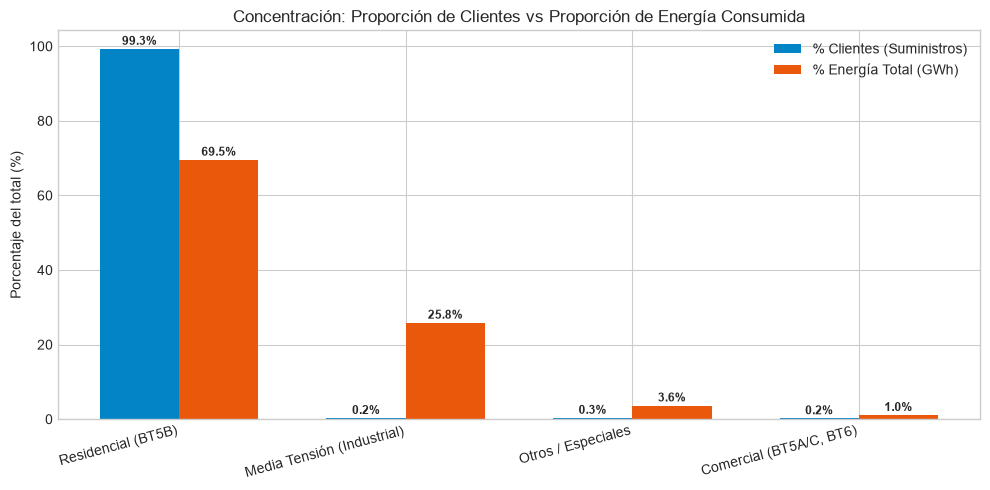

In [8]:
def clasificar_tarifa_expr():
    return (
        pl.when(pl.col("TARIFA").str.to_uppercase() == "BT5B").then(pl.lit("Residencial (BT5B)"))
        .when(pl.col("TARIFA").str.to_uppercase().is_in(["BT5A", "BT5C", "BT6"])).then(pl.lit("Comercial (BT5A/C, BT6)"))
        .when(pl.col("TARIFA").str.to_uppercase().str.starts_with("MT")).then(pl.lit("Media Tensión (Industrial)"))
        .when(pl.col("TARIFA").str.to_uppercase().str.starts_with("AP")).then(pl.lit("Alumbrado Público"))
        .otherwise(pl.lit("Otros / Especiales"))
    )

resumen_tarifas = (
    df.with_columns(clasificar_tarifa_expr().alias("GRUPO_TARIFA"))
    .group_by("GRUPO_TARIFA")
    .agg([
        pl.len().alias("total_facturas"),
        (pl.col("CONSUMO").sum() / 1e6).round(2).alias("energia_gwh"),
        (pl.col("IMPORTE").sum() / 1e6).round(2).alias("importe_millones"),
        pl.col("CONSUMO").median().round(1).alias("mediana_kwh"),
    ])
    .with_columns([
        (pl.col("total_facturas") / total_registros * 100).round(2).alias("pct_clientes"),
        (pl.col("energia_gwh") / total_gwh * 100).round(2).alias("pct_energia"),
    ])
    .sort("energia_gwh", descending=True)
    .collect()
)

display(resumen_tarifas.to_pandas())

# Gráfico de Pareto anotado: % Clientes vs % Energía por grupo tarifario
t_pd = resumen_tarifas.to_pandas()
x = np.arange(len(t_pd))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
b1 = ax.bar(x - width/2, t_pd["pct_clientes"], width, label="% Clientes (Suministros)", color="#0284c7")
b2 = ax.bar(x + width/2, t_pd["pct_energia"], width, label="% Energía Total (GWh)", color="#ea580c")

ax.set_xticks(x)
ax.set_xticklabels(t_pd["GRUPO_TARIFA"], rotation=15, ha="right")
ax.set_ylabel("Porcentaje del total (%)")
ax.set_title("Concentración: Proporción de Clientes vs Proporción de Energía Consumida")
ax.legend()

for b in b1:
    ax.annotate(f"{b.get_height():.1f}%", xy=(b.get_x() + b.get_width()/2, b.get_height()),
                xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5, fontweight="bold")
for b in b2:
    ax.annotate(f"{b.get_height():.1f}%", xy=(b.get_x() + b.get_width()/2, b.get_height()),
                xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.show()


## 6. Dinámica Temporal: Demanda Histórica y Estacionalidad Intra-anual

Analizamos la dinámica temporal a través de dos visualizaciones clave:
1. **Series Temporales Mensuales (2022–2026)**: Evolución cronológica de la demanda total facturada (GWh) y del padrón mensual de clientes activos.
2. **Comparación Estacional Intra-anual (Ene–Dic por Año)**: Desglose mes a mes para cada distribuidora, permitiendo contrastar el pico veraniego de la costa norte con el perfil de sierra.


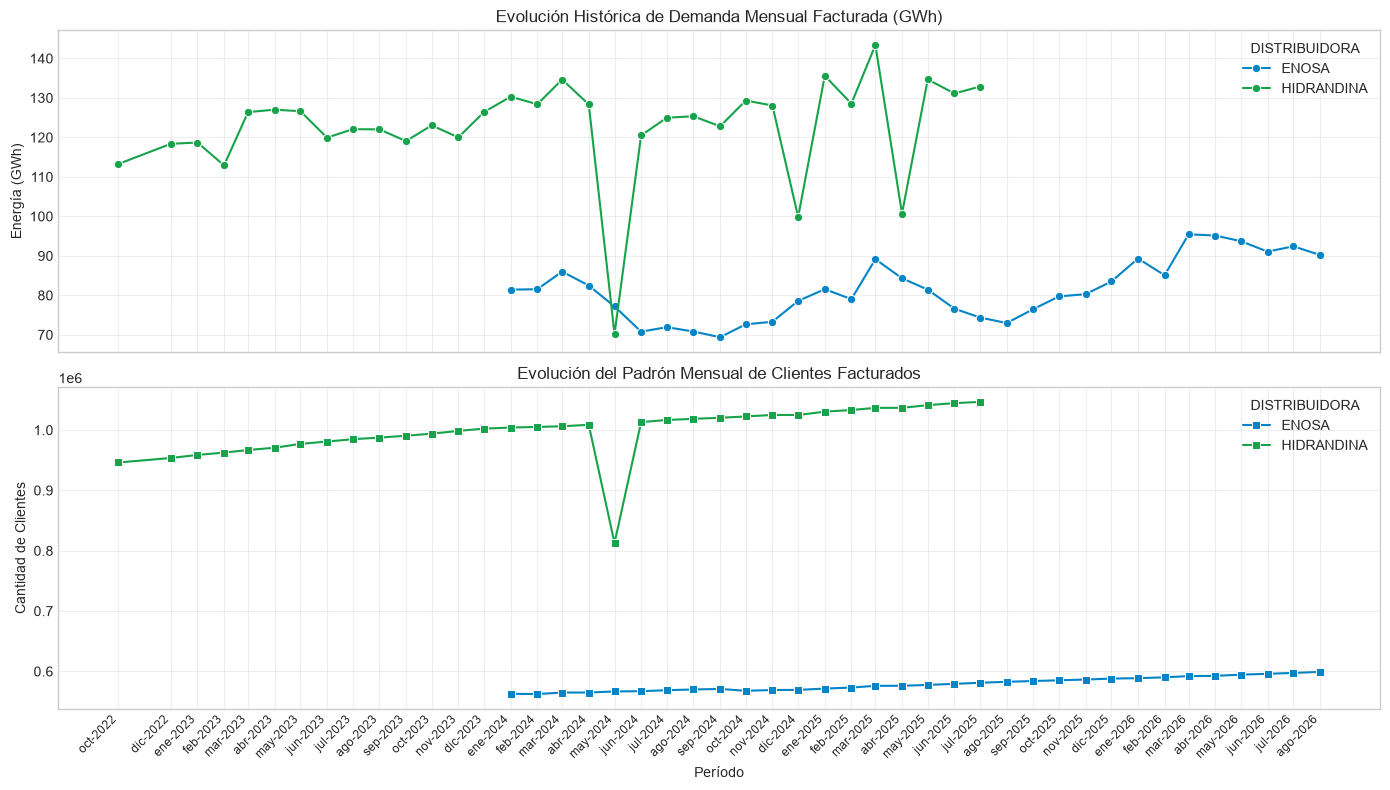

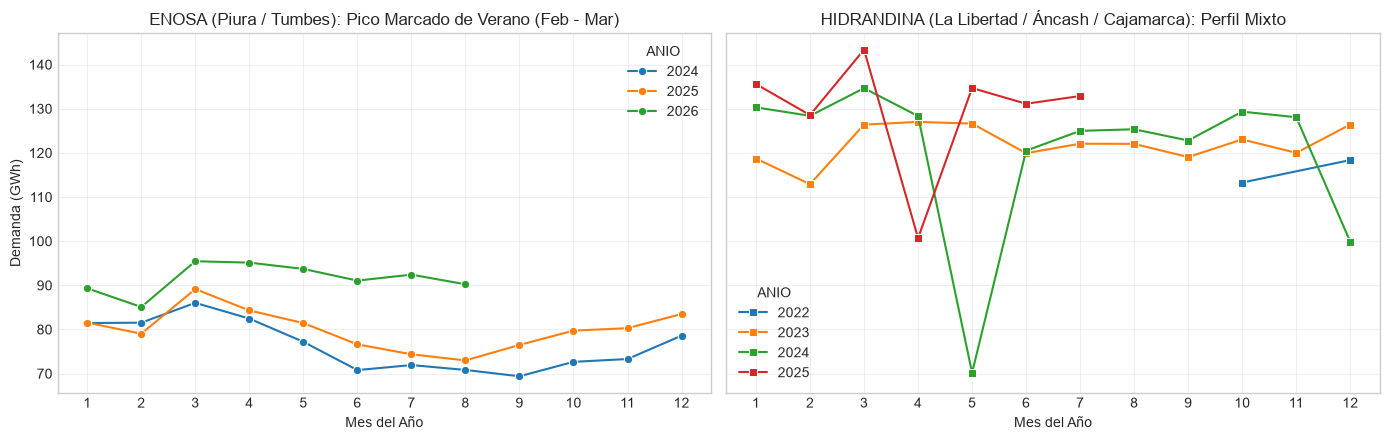

In [9]:
# 1. Agregación mensual por distribuidora y conversión a fecha
serie_mensual = (
    df.group_by(["DISTRIBUIDORA", "PERIODO"])
    .agg([
        (pl.col("CONSUMO").sum() / 1e6).alias("energia_gwh"),
        (pl.col("IMPORTE").sum() / 1e6).alias("importe_millones"),
        pl.len().alias("clientes"),
    ])
    .with_columns(
        pl.col("PERIODO").cast(pl.String).str.strptime(pl.Date, format="%Y%m").alias("FECHA")
    )
    .sort(["DISTRIBUIDORA", "FECHA"])
    .collect()
)

ts_pd = serie_mensual.to_pandas()

# Gráfico 1: Evolución temporal de demanda y clientes (2022-2026)
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

sns.lineplot(data=ts_pd, x="FECHA", y="energia_gwh", hue="DISTRIBUIDORA", marker="o", ax=axes[0], palette={"ENOSA": "#0284c7", "HIDRANDINA": "#16a34a"})
axes[0].set_title("Evolución Histórica de Demanda Mensual Facturada (GWh)")
axes[0].set_ylabel("Energía (GWh)")
axes[0].set_xlabel("")
axes[0].grid(True, alpha=0.3)

sns.lineplot(data=ts_pd, x="FECHA", y="clientes", hue="DISTRIBUIDORA", marker="s", ax=axes[1], palette={"ENOSA": "#0284c7", "HIDRANDINA": "#16a34a"})
axes[1].set_title("Evolución del Padrón Mensual de Clientes Facturados")
axes[1].set_ylabel("Cantidad de Clientes")
axes[1].set_xlabel("Período")
axes[1].grid(True, alpha=0.3)

fechas_unicas = ts_pd["FECHA"].drop_duplicates().sort_values()
meses_nombres = {1: "ene", 2: "feb", 3: "mar", 4: "abr", 5: "may", 6: "jun", 7: "jul", 8: "ago", 9: "sep", 10: "oct", 11: "nov", 12: "dic"}
axes[1].set_xticks(fechas_unicas)
axes[1].set_xticklabels([f"{meses_nombres[f.month]}-{f.year}" for f in fechas_unicas], rotation=45, ha="right", fontsize=8.5)

plt.tight_layout()
plt.show()

# Gráfico 2: Estacionalidad intra-anual por mes del año (1 a 12)
ts_pd["ANIO"] = ts_pd["FECHA"].dt.year
ts_pd["MES"] = ts_pd["FECHA"].dt.month

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)

# ENOSA
sns.lineplot(data=ts_pd[ts_pd["DISTRIBUIDORA"] == "ENOSA"], x="MES", y="energia_gwh", hue="ANIO", marker="o", ax=axes[0], palette="tab10")
axes[0].set_title("ENOSA (Piura / Tumbes): Pico Marcado de Verano (Feb - Mar)")
axes[0].set_xlabel("Mes del Año")
axes[0].set_ylabel("Demanda (GWh)")
axes[0].set_xticks(range(1, 13))
axes[0].grid(True, alpha=0.3)

# HIDRANDINA
sns.lineplot(data=ts_pd[ts_pd["DISTRIBUIDORA"] == "HIDRANDINA"], x="MES", y="energia_gwh", hue="ANIO", marker="s", ax=axes[1], palette="tab10")
axes[1].set_title("HIDRANDINA (La Libertad / Áncash / Cajamarca): Perfil Mixto")
axes[1].set_xlabel("Mes del Año")
axes[1].set_xticks(range(1, 13))
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 7. Evolución por Departamento y Ranking de Distritos

Examinamos la distribución territorial de la demanda a nivel regional:
1. **Ranking del Top 15 de Distritos**: Identificación de los principales centros urbanos e industriales de carga eléctrica (Trujillo, Piura, Chimbote, Chiclayo, Sullana, etc.). (MAPA INTERACTIVO MAS ADELANTE)
2. **Evolución Temporal por Departamento**: Curvas históricas de demanda mensual agrupadas por departamento geográfico.


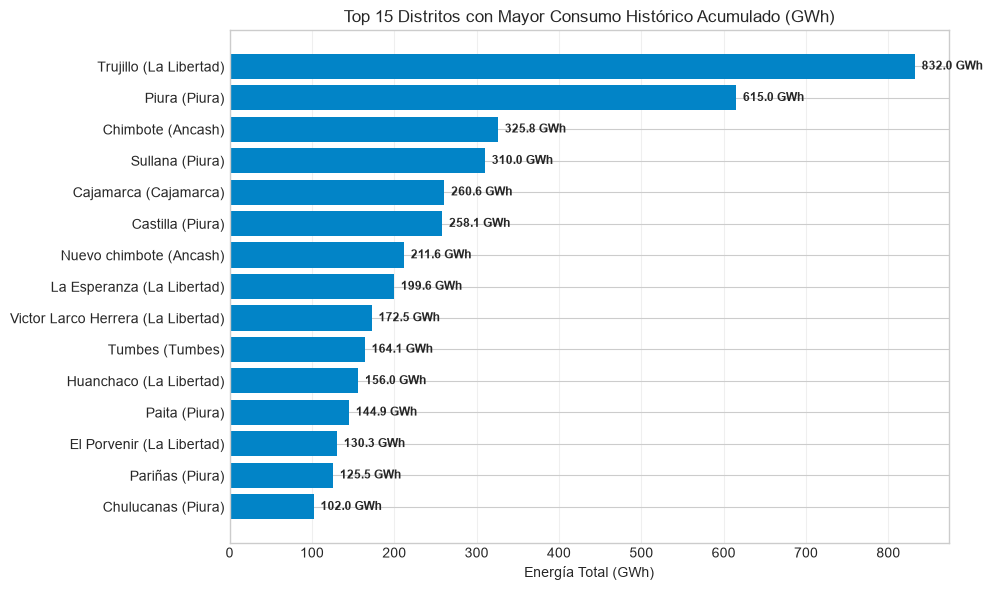

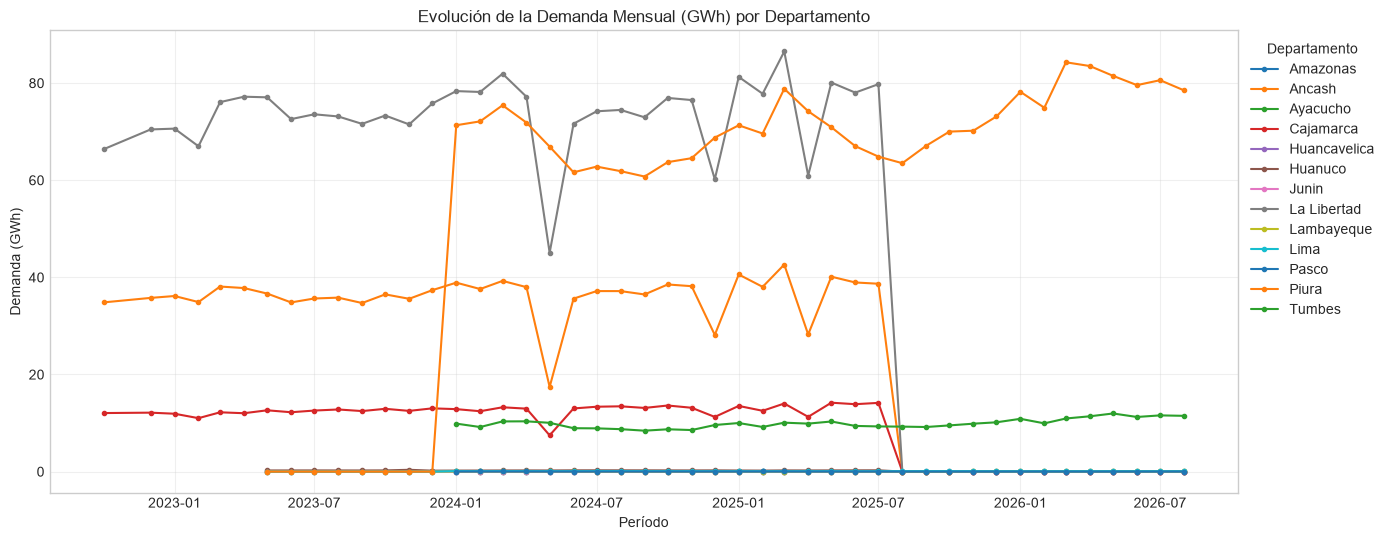

In [10]:
# 1. Ranking de los 15 distritos con mayor demanda acumulada
top15_distritos = (
    df.group_by(["UBIGEO", "DISTRITO", "DEPARTAMENTO"])
    .agg([
        (pl.col("CONSUMO").sum() / 1e6).round(2).alias("energia_gwh"),
        pl.len().alias("total_facturas"),
    ])
    .sort("energia_gwh", descending=True)
    .head(15)
    .collect()
    .to_pandas()
)

fig, ax = plt.subplots(figsize=(10, 6))
top_plot = top15_distritos.sort_values("energia_gwh", ascending=True)
bars = ax.barh(top_plot["DISTRITO"] + " (" + top_plot["DEPARTAMENTO"] + ")", top_plot["energia_gwh"], color="#0284c7")
ax.set_title("Top 15 Distritos con Mayor Consumo Histórico Acumulado (GWh)")
ax.set_xlabel("Energía Total (GWh)")
ax.grid(axis="x", alpha=0.3)

for b in bars:
    ax.annotate(f"{b.get_width():,.1f} GWh", xy=(b.get_width(), b.get_y() + b.get_height()/2),
                xytext=(5, 0), textcoords="offset points", va="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.show()

# 2. Evolución temporal de demanda mensual por Departamento
depto_time = (
    df.group_by(["DEPARTAMENTO", "PERIODO"])
    .agg((pl.col("CONSUMO").sum() / 1e6).alias("energia_gwh"))
    .with_columns(
        pl.col("PERIODO").cast(pl.String).str.strptime(pl.Date, format="%Y%m").alias("FECHA")
    )
    .sort(["DEPARTAMENTO", "FECHA"])
    .collect()
    .to_pandas()
)

fig, ax = plt.subplots(figsize=(14, 5.5))
for depto, grupo in depto_time.groupby("DEPARTAMENTO"):
    grupo = grupo.sort_values("FECHA")
    ax.plot(grupo["FECHA"], grupo["energia_gwh"], marker=".", label=str(depto), linewidth=1.5)

ax.set_title("Evolución de la Demanda Mensual (GWh) por Departamento")
ax.set_xlabel("Período")
ax.set_ylabel("Demanda (GWh)")
ax.legend(title="Departamento", loc="upper left", bbox_to_anchor=(1, 1))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 8. Patrones Mensuales, Estabilidad del Pico y Heatmap Estacional de Tarifas

Profundizamos en el análisis de estacionalidad calculando:
1. **Mes típico de pico y estabilidad interanual por distrito**: Para cada distrito evaluamos qué mes del año (1 a 12) presenta recurrentemente el mayor consumo y qué porcentaje de años (`estabilidad_pico_pct`) se repitió en dicho mes.
2. **Heatmap de Tarifas vs Mes del Año**: Matriz normalizada que expone el índice de estacionalidad mensual para cada categoría tarifaria (valores > 1.0 indican meses por encima del promedio anual).


Top 10 distritos con mayor demanda y su estabilidad del mes pico interanual:


,UBIGEO,distrito,departamento,consumo_pico_mwh,mes_pico,mes_valle,mes_pico_tipico,estabilidad_pico_pct,ratio_estacional
312,130101,Trujillo,La Libertad,29167.150391,202503,202509,3,40.0,1323.969971
444,200101,Piura,Piura,23436.539062,202603,202409,3,100.0,1.440000
639,21801,Chimbote,Ancash,11868.639648,202503,202405,3,75.0,1.790000
489,200601,Sullana,Piura,11198.250000,202603,202409,3,100.0,1.330000
445,200104,Castilla,Piura,10107.509766,202603,202312,3,75.0,10107.509766
131,021801,Chimbote,Ancash,9624.519531,202210,202210,10,100.0,1.000000
688,60101,Cajamarca,Cajamarca,9130.389648,202505,202405,12,50.0,2.380000
171,060101,Cajamarca,Cajamarca,7931.859863,202210,202410,4,25.0,7931.859863
647,21809,Nuevo chimbote,Ancash,7695.750000,202503,202405,3,50.0,7.740000
316,130105,La Esperanza,La Libertad,7192.919922,202503,202509,3,40.0,4133.859863


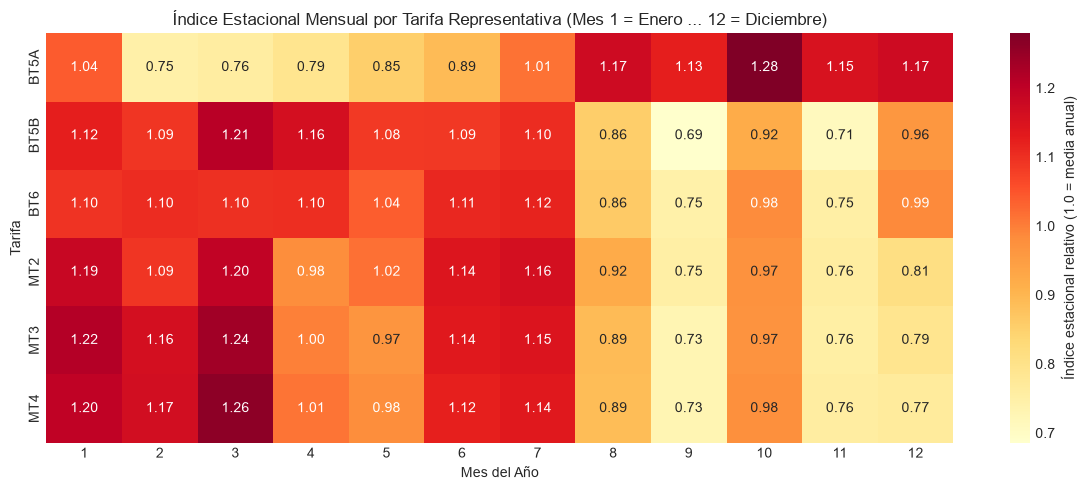

In [11]:
# 1. Agregación distrital por año y mes para evaluar la estabilidad del pico
mensual_dist = (
    df.group_by(["UBIGEO", "PERIODO"])
    .agg([
        pl.col("CONSUMO").sum().alias("consumo_total"),
        pl.first("DISTRITO").alias("DISTRITO"),
        pl.first("DEPARTAMENTO").alias("DEPARTAMENTO"),
    ])
    .collect()
    .to_pandas()
)
mensual_dist["Anio"] = mensual_dist["PERIODO"].astype(str).str[:4].astype(int)
mensual_dist["Mes"] = mensual_dist["PERIODO"].astype(str).str[4:].astype(int)

# Mes pico anual por distrito
peak_by_year = (
    mensual_dist.sort_values(["UBIGEO", "Anio", "consumo_total"], ascending=[True, True, False])
    .groupby(["UBIGEO", "Anio"])
    .first()
    .reset_index()
)

def calc_peak_stability(s):
    mode = s.mode()
    m_val = mode.iloc[0] if len(mode) > 0 else s.iloc[0]
    rep = (s == m_val).sum()
    return pd.Series({"mes_pico_tipico": int(m_val), "anios_pico_repetido": rep, "anios_historia": len(s)})

picos_estabilidad = peak_by_year.groupby("UBIGEO")["Mes"].apply(calc_peak_stability).unstack().reset_index()
picos_estabilidad["estabilidad_pico_pct"] = (picos_estabilidad["anios_pico_repetido"] / picos_estabilidad["anios_historia"] * 100).round(1)

# Extremos globales por distrito
picos_globales = (
    mensual_dist.sort_values(["UBIGEO", "consumo_total"], ascending=[True, False])
    .groupby("UBIGEO")
    .agg(
        distrito=("DISTRITO", "first"),
        departamento=("DEPARTAMENTO", "first"),
        consumo_pico_mwh=("consumo_total", lambda s: round(s.iloc[0] / 1000, 2)),
        consumo_valle_mwh=("consumo_total", lambda s: round(s.iloc[-1] / 1000, 2)),
        mes_pico=("PERIODO", "first"),
        mes_valle=("PERIODO", "last"),
    )
    .reset_index()
)

df_patrones = picos_globales.merge(picos_estabilidad, on="UBIGEO")
df_patrones["ratio_estacional"] = (df_patrones["consumo_pico_mwh"] / df_patrones["consumo_valle_mwh"].clip(lower=1)).round(2)

print("Top 10 distritos con mayor demanda y su estabilidad del mes pico interanual:")
display(df_patrones.sort_values("consumo_pico_mwh", ascending=False).head(10)[
    ["UBIGEO", "distrito", "departamento", "consumo_pico_mwh", "mes_pico", "mes_valle", "mes_pico_tipico", "estabilidad_pico_pct", "ratio_estacional"]
])

# 2. Heatmap de Tarifa vs Mes del Año (Índice de Estacionalidad Normalizado)
top_tarifas_analisis = ["BT5B", "MT2", "MT3", "MT4", "BT5A", "BT6", "AP"]

t_mes = (
    df.filter(pl.col("TARIFA").str.to_uppercase().is_in(top_tarifas_analisis) & (pl.col("CONSUMO") > 0))
    .with_columns([
        pl.col("PERIODO").cast(pl.String).str.slice(4, 2).cast(pl.Int32).alias("MES"),
        pl.col("TARIFA").str.to_uppercase().alias("TARIFA_NORM")
    ])
    .group_by(["TARIFA_NORM", "MES"])
    .agg((pl.col("CONSUMO").sum() / 1e6).alias("energia_gwh"))
    .collect()
    .to_pandas()
)

matrix_tarifa = t_mes.pivot_table(index="TARIFA_NORM", columns="MES", values="energia_gwh", fill_value=0)
norm_tarifa = matrix_tarifa.div(matrix_tarifa.mean(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(norm_tarifa, annot=True, fmt=".2f", cmap="YlOrRd", cbar_kws={"label": "Índice estacional relativo (1.0 = media anual)"}, ax=ax)
ax.set_title("Índice Estacional Mensual por Tarifa Representativa (Mes 1 = Enero ... 12 = Diciembre)")
ax.set_xlabel("Mes del Año")
ax.set_ylabel("Tarifa")
plt.tight_layout()
plt.show()


## 9. Evaluación de la Formulación ML: `UBIGEO × Tarifa × Periodo`

Evaluamos si la combinación `UBIGEO × Tarifa × Periodo` constituye una unidad de análisis densa y continua para entrenar modelos predictivos (regresión tabular o series temporales).
Graficamos la distribución del número de meses activos para determinar cuántas series alcanzan horizontes históricos completos.


In [12]:
t0 = time.time()
triple_df = (
    df.group_by(["UBIGEO", "TARIFA", "PERIODO"])
    .agg([
        pl.len().alias("n_registros"),
        (pl.col("CONSUMO").sum() / 1e3).round(2).alias("consumo_total_mwh"),
        (pl.col("IMPORTE").sum() / 1e3).round(2).alias("importe_total_miles"),
        pl.col("CONSUMO").median().round(1).alias("consumo_mediano"),
        pl.first("DISTRIBUIDORA").alias("DISTRIBUIDORA"),
    ])
    .collect()
)
t_triple = time.time() - t0

print(f"Cubo 'UBIGEO × Tarifa × Periodo' generado en {t_triple:.2f}s:")
print(f" - Total observaciones agregadas: {len(triple_df):,}")
print(f" - Distritos únicos con datos:     {triple_df['UBIGEO'].n_unique()}")
print(f" - Tarifas únicas presentes:       {triple_df['TARIFA'].n_unique()}")
print(f" - Períodos mensuales cubiertos:   {triple_df['PERIODO'].n_unique()}")


Cubo 'UBIGEO × Tarifa × Periodo' generado en 5.60s:
 - Total observaciones agregadas: 44,152
 - Distritos únicos con datos:     770
 - Tarifas únicas presentes:       15
 - Períodos mensuales cubiertos:   46


## 10. Relación de las variables candidatas con el consumo

A partir del feedback recibido, en esta sección analizamos de forma más directa si las variables que pensamos utilizar en el modelo realmente presentan diferencias o patrones asociados con el consumo eléctrico.

El objetivo no es entrenar todavía un modelo, sino responder cuatro preguntas sencillas:

1. ¿El consumo cambia según la **Tarifa**?
2. ¿El consumo cambia según el **UBIGEO**?
3. ¿El consumo presenta diferencias según el **mes o periodo**?
4. ¿El consumo de meses anteriores tiene relación con el consumo de un mes posterior?

Estas comprobaciones nos permiten justificar mejor por qué estas variables son candidatas para la etapa de Machine Learning.

### 10.1. Tarifa y consumo

Primero comparamos el consumo mensual entre las distintas tarifas. Si los niveles de consumo cambian de forma importante entre categorías, entonces `TARIFA` contiene información útil para explicar el comportamiento de la demanda.

Como el dataset está fuertemente desbalanceado hacia BT5B, además del número de observaciones revisamos la mediana y el promedio del consumo agregado mensual.

,TARIFA,observaciones_mensuales,consumo_promedio_mwh,consumo_mediano_mwh,consumo_std_mwh,ubigeos,periodos
0,MT2E,32,89.019997,97.629997,22.730000,1,32
1,AT2,60,87.269997,77.260002,29.330000,3,30
2,MT2,3879,75.070000,19.540001,140.440002,161,46
3,BT5B,16059,288.029999,16.670000,1269.040039,759,46
4,BT5E,226,25.980000,14.600000,30.959999,7,46
5,MT3,7304,165.289993,9.100000,481.859985,348,46
6,BT3,2389,55.830002,7.800000,148.160004,100,46
7,BT5A,688,18.330000,6.760000,32.830002,27,46
8,BT5D,1262,30.730000,5.390000,91.459999,75,46
9,MT4,5584,38.779999,5.160000,130.729996,292,46


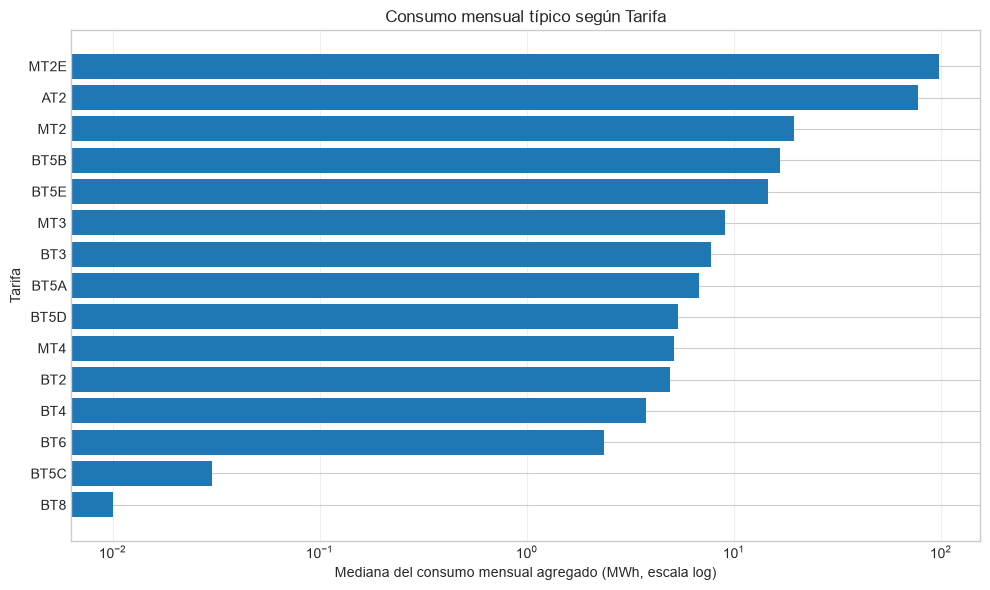

In [13]:
# Relación entre TARIFA y el consumo agregado mensual
rel_tarifa_consumo = (
    triple_df.group_by("TARIFA")
    .agg([
        pl.len().alias("observaciones_mensuales"),
        pl.col("consumo_total_mwh").mean().round(2).alias("consumo_promedio_mwh"),
        pl.col("consumo_total_mwh").median().round(2).alias("consumo_mediano_mwh"),
        pl.col("consumo_total_mwh").std().round(2).alias("consumo_std_mwh"),
        pl.col("UBIGEO").n_unique().alias("ubigeos"),
        pl.col("PERIODO").n_unique().alias("periodos"),
    ])
    .sort("consumo_mediano_mwh", descending=True)
)

display(rel_tarifa_consumo.to_pandas())

tarifa_plot = rel_tarifa_consumo.to_pandas().sort_values("consumo_mediano_mwh", ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(tarifa_plot["TARIFA"], tarifa_plot["consumo_mediano_mwh"])
ax.set_xscale("log")
ax.set_xlabel("Mediana del consumo mensual agregado (MWh, escala log)")
ax.set_ylabel("Tarifa")
ax.set_title("Consumo mensual típico según Tarifa")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### 10.2. UBIGEO y consumo

Luego revisamos si existen diferencias de consumo entre zonas geográficas. Para evitar que una tarifa con muchos registros domine el resultado, primero sumamos el consumo de todas las tarifas por `UBIGEO` y `PERIODO`, y después resumimos el comportamiento histórico de cada zona.

Si los UBIGEO muestran niveles de consumo distintos entre sí, la ubicación geográfica aporta señal relevante para el futuro modelo.

UBIGEO con mayor consumo mensual típico:


,UBIGEO,periodos,consumo_promedio_mwh,consumo_mediano_mwh,consumo_std_mwh
0,130101,46,18086.279297,24579.099609,11690.440430
1,200101,32,19217.759766,18783.179688,2079.580078
2,21801,32,10180.169922,10253.129883,1142.510010
3,200601,32,9686.389648,9638.179688,775.710022
4,021801,1,9624.530273,9624.530273,NaN
5,60101,32,8144.359863,8310.379883,930.440002
6,200104,40,6452.049805,7808.540039,3352.959961
7,21809,32,6614.189941,6718.620117,1085.109985
8,130105,46,4338.700195,5957.540039,2794.219971
9,130111,46,3750.800049,5111.379883,2398.459961


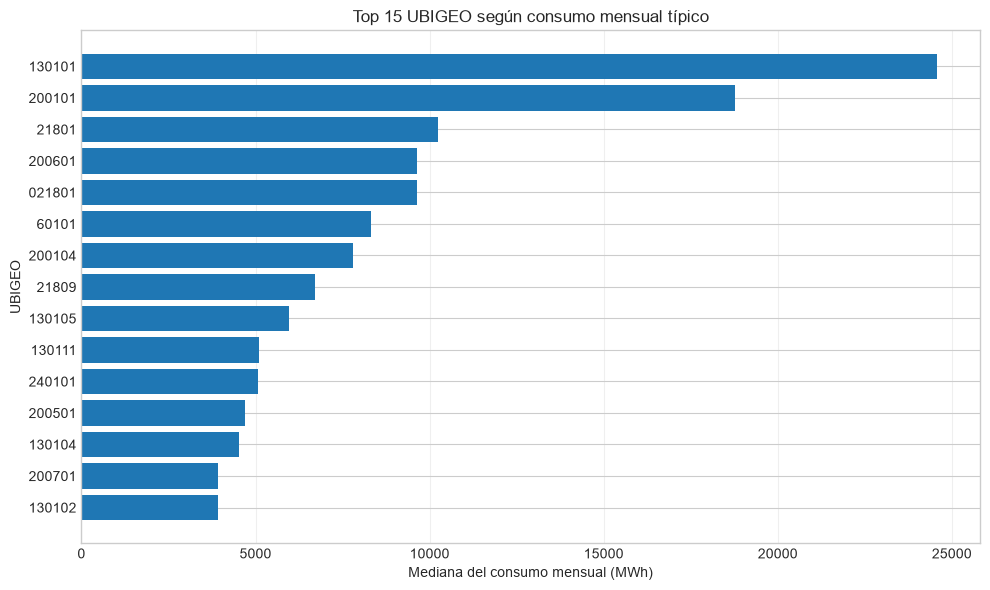

In [14]:
# Consumo total mensual por UBIGEO, sumando sus distintas tarifas
ubigeo_periodo = (
    triple_df.group_by(["UBIGEO", "PERIODO"])
    .agg(
        pl.col("consumo_total_mwh").sum().round(2).alias("consumo_total_mwh")
    )
)

rel_ubigeo_consumo = (
    ubigeo_periodo.group_by("UBIGEO")
    .agg([
        pl.len().alias("periodos"),
        pl.col("consumo_total_mwh").mean().round(2).alias("consumo_promedio_mwh"),
        pl.col("consumo_total_mwh").median().round(2).alias("consumo_mediano_mwh"),
        pl.col("consumo_total_mwh").std().round(2).alias("consumo_std_mwh"),
    ])
    .sort("consumo_mediano_mwh", descending=True)
)

print("UBIGEO con mayor consumo mensual típico:")
display(rel_ubigeo_consumo.head(15).to_pandas())

top_ubigeo_plot = (
    rel_ubigeo_consumo.head(15)
    .to_pandas()
    .sort_values("consumo_mediano_mwh", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_ubigeo_plot["UBIGEO"].astype(str), top_ubigeo_plot["consumo_mediano_mwh"])
ax.set_xlabel("Mediana del consumo mensual (MWh)")
ax.set_ylabel("UBIGEO")
ax.set_title("Top 15 UBIGEO según consumo mensual típico")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### 10.3. Temporalidad y consumo

También queremos comprobar si el mes del año está relacionado con cambios en el consumo. Para ello comparamos el consumo agregado de las combinaciones `UBIGEO × TARIFA` según el mes calendario.

Este análisis ayuda a sustentar el uso de variables temporales como mes y año, y permite observar si existen meses que tienden a presentar niveles de consumo diferentes.

,MES,observaciones,consumo_promedio_mwh,consumo_mediano_mwh,consumo_std_mwh
0,1,4144,153.690002,9.11,803.349976
1,2,4147,148.419998,8.43,790.390015
2,3,4149,162.699997,8.99,882.030029
3,4,3732,165.580002,9.43,880.130005
4,5,3723,156.820007,9.51,826.239990
5,6,4198,145.309998,8.86,776.119995
6,7,4208,147.020004,9.01,783.820007
7,8,3320,145.000000,8.50,758.830017
8,9,2815,137.740005,8.77,730.400024
9,10,3656,141.690002,9.49,756.489990


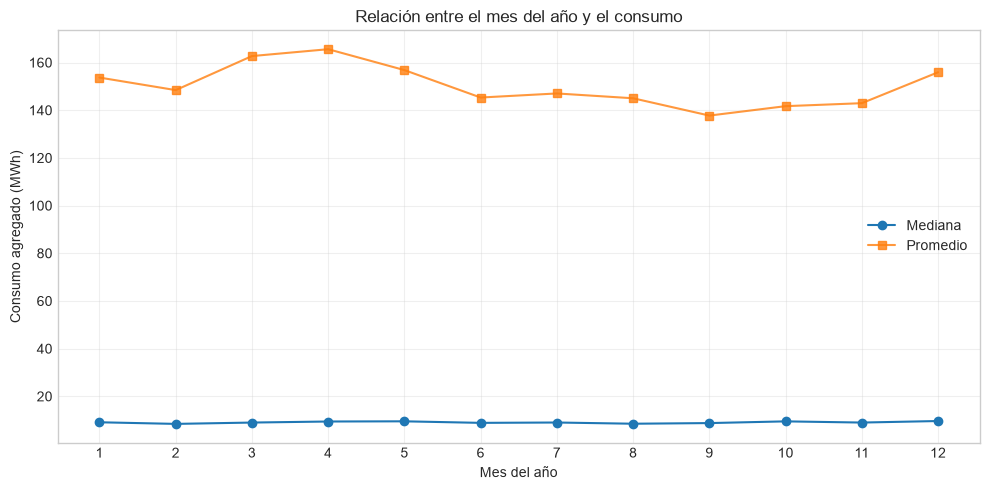

In [15]:
# Relación entre MES DEL AÑO y consumo
rel_mes_consumo = (
    triple_df
    .with_columns(
        pl.col("PERIODO")
        .cast(pl.String)
        .str.slice(4, 2)
        .cast(pl.Int32)
        .alias("MES")
    )
    .group_by("MES")
    .agg([
        pl.len().alias("observaciones"),
        pl.col("consumo_total_mwh").mean().round(2).alias("consumo_promedio_mwh"),
        pl.col("consumo_total_mwh").median().round(2).alias("consumo_mediano_mwh"),
        pl.col("consumo_total_mwh").std().round(2).alias("consumo_std_mwh"),
    ])
    .sort("MES")
)

display(rel_mes_consumo.to_pandas())

mes_plot = rel_mes_consumo.to_pandas()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    mes_plot["MES"],
    mes_plot["consumo_mediano_mwh"],
    marker="o",
    label="Mediana"
)
ax.plot(
    mes_plot["MES"],
    mes_plot["consumo_promedio_mwh"],
    marker="s",
    alpha=0.8,
    label="Promedio"
)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Mes del año")
ax.set_ylabel("Consumo agregado (MWh)")
ax.set_title("Relación entre el mes del año y el consumo")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 10.4. Consumo histórico y consumo de meses posteriores

Finalmente evaluamos una señal especialmente importante para el problema predictivo: si el consumo de una combinación `UBIGEO × TARIFA` en meses anteriores está relacionado con su consumo en un mes posterior.

Para cada observación mensual calculamos dos referencias históricas:

- `lag_1`: consumo del mes inmediatamente anterior.
- `lag_12`: consumo del mismo mes del año anterior.

Estas variables todavía no se utilizarán para entrenar ningún modelo; únicamente comprobamos si existe suficiente relación temporal como para considerarlas en la siguiente fase.

,relacion,correlacion_pearson,pares_validos
0,Consumo actual vs mes anterior (lag_1),0.987072,40389
1,Consumo actual vs mismo mes del año anterior (...,0.860912,25574


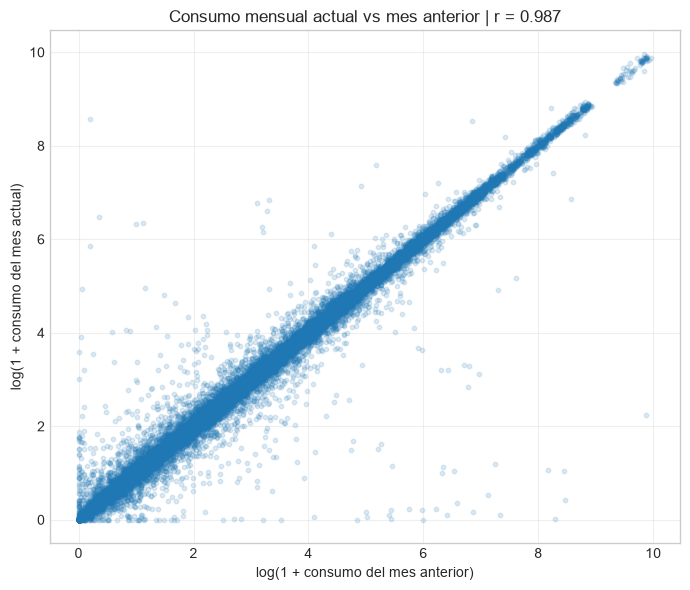

Correlación con el mes anterior (lag_1): 0.9871
Correlación con el mismo mes del año anterior (lag_12): 0.8609


In [16]:
# Base mensual ordenada para analizar dependencia temporal
serie_base = (
    triple_df
    .select(["UBIGEO", "TARIFA", "PERIODO", "consumo_total_mwh"])
    .with_columns([
        (
            pl.col("PERIODO").cast(pl.Int32).floordiv(100) * 12
            + pl.col("PERIODO").cast(pl.Int32).mod(100)
        ).alias("mes_idx")
    ])
)

# Consumo del mes anterior (t-1)
lag1 = (
    serie_base
    .select([
        "UBIGEO",
        "TARIFA",
        (pl.col("mes_idx") + 1).alias("mes_idx"),
        pl.col("consumo_total_mwh").alias("lag_1_mwh"),
    ])
)

# Consumo del mismo mes del año anterior (t-12)
lag12 = (
    serie_base
    .select([
        "UBIGEO",
        "TARIFA",
        (pl.col("mes_idx") + 12).alias("mes_idx"),
        pl.col("consumo_total_mwh").alias("lag_12_mwh"),
    ])
)

serie_lags = (
    serie_base
    .join(lag1, on=["UBIGEO", "TARIFA", "mes_idx"], how="left")
    .join(lag12, on=["UBIGEO", "TARIFA", "mes_idx"], how="left")
)

corr_lag1 = (
    serie_lags
    .filter(pl.col("lag_1_mwh").is_not_null())
    .select(pl.corr("consumo_total_mwh", "lag_1_mwh").alias("corr_lag1"))
    .item()
)

corr_lag12 = (
    serie_lags
    .filter(pl.col("lag_12_mwh").is_not_null())
    .select(pl.corr("consumo_total_mwh", "lag_12_mwh").alias("corr_lag12"))
    .item()
)

n_lag1 = serie_lags.filter(pl.col("lag_1_mwh").is_not_null()).height
n_lag12 = serie_lags.filter(pl.col("lag_12_mwh").is_not_null()).height

resumen_lags = pd.DataFrame({
    "relacion": [
        "Consumo actual vs mes anterior (lag_1)",
        "Consumo actual vs mismo mes del año anterior (lag_12)",
    ],
    "correlacion_pearson": [corr_lag1, corr_lag12],
    "pares_validos": [n_lag1, n_lag12],
})

display(resumen_lags)

# Visualización en escala logarítmica para reducir el efecto de valores extremos
lags_pd = (
    serie_lags
    .filter(pl.col("lag_1_mwh").is_not_null())
    .select(["consumo_total_mwh", "lag_1_mwh"])
    .to_pandas()
)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(
    np.log1p(lags_pd["lag_1_mwh"]),
    np.log1p(lags_pd["consumo_total_mwh"]),
    alpha=0.15,
    s=10,
)
ax.set_xlabel("log(1 + consumo del mes anterior)")
ax.set_ylabel("log(1 + consumo del mes actual)")
ax.set_title(f"Consumo mensual actual vs mes anterior | r = {corr_lag1:.3f}")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Correlación con el mes anterior (lag_1): {corr_lag1:.4f}")
print(f"Correlación con el mismo mes del año anterior (lag_12): {corr_lag12:.4f}")

## 11. Mapa Interactivo Distrital de Demanda (100% Libre / 0 API Keys)

Generación de un mapa coroplético interactivo con **Leaflet 1.9.4** utilizando los polígonos distritales de `distritos_concesion.geojson`.

**Garantía de Cero API Key**:
- Se utilizan servidores de teselas totalmente libres y públicos: **Esri World Dark Gray Canvas** y **OpenStreetMap Estándar**.
- No requiere cuentas, tokens ni claves de acceso.
- Cada distrito incluye un panel interactivo con: demanda acumulada en GWh, total de facturas, consumo mediano, porcentaje del total del sistema y sus meses pico y valle estacionales.


In [17]:
# 1. Agregación distrital general para el mapa
por_distrito = (
    df.group_by(["UBIGEO"])
    .agg([
        pl.len().alias("facturas"),
        (pl.col("CONSUMO").sum() / 1e6).round(2).alias("energia_gwh"),
        pl.col("CONSUMO").median().round(1).alias("mediana_consumo"),
        pl.first("DEPARTAMENTO").alias("DEPARTAMENTO"),
        pl.first("PROVINCIA").alias("PROVINCIA"),
        pl.first("DISTRITO").alias("DISTRITO"),
        pl.first("DISTRIBUIDORA").alias("DISTRIBUIDORA"),
    ])
    .collect()
)

# Diccionario de estacionalidad por UBIGEO a 6 dígitos
picos_map = {str(r["UBIGEO"]).strip().zfill(6): r for r in df_patrones.to_dict(orient="records")}

metrics_map = {}
for row in por_distrito.iter_rows(named=True):
    u = str(row["UBIGEO"]).strip().zfill(6)
    est = picos_map.get(u, {})
    metrics_map[u] = {
        "distribuidora": row["DISTRIBUIDORA"],
        "departamento": row["DEPARTAMENTO"],
        "provincia": row["PROVINCIA"],
        "distrito": row["DISTRITO"],
        "gwh": float(row["energia_gwh"]),
        "facturas": int(row["facturas"]),
        "mediana_kwh": float(row["mediana_consumo"]),
        "pct": round(float(row["energia_gwh"] / total_gwh * 100), 2),
        "mes_pico": str(est.get("mes_pico", "N/A")),
        "mes_valle": str(est.get("mes_valle", "N/A")),
        "ratio_estacional": float(est.get("ratio_estacional", 1.0)),
    }

# 2. Cargar y enriquecer GeoJSON oficial
with open(GEOJSON_PATH, encoding="utf-8") as f:
    geo = json.load(f)

for feat in geo["features"]:
    u = str(feat["properties"].get("ubigeo", "")).strip().zfill(6)
    if u in metrics_map:
        feat["properties"].update(metrics_map[u])
        feat["properties"]["has_data"] = True
    else:
        feat["properties"]["has_data"] = False
        feat["properties"]["gwh"] = 0.0

geo_json_str = json.dumps(geo, ensure_ascii=False)
map_html_path = OUTPUT_DIR / "mapa_distrital_energia.html"

# 3. HTML interactivo con Leaflet (OpenStreetMap / Esri Canvas libres)
html_content = f"""<!DOCTYPE html>
<html lang="es">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Demanda Eléctrica por Distritos - ENOSA e Hidrandina</title>
    <link rel="stylesheet" href="https://unpkg.com/leaflet@1.9.4/dist/leaflet.css" />
    <style>
        body {{ margin: 0; padding: 0; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; background: #0f172a; color: #f8fafc; }}
        #map {{ width: 100%; height: 620px; }}
        .info-panel {{ padding: 12px 16px; background: rgba(15, 23, 42, 0.95); border: 1px solid rgba(255, 255, 255, 0.15); box-shadow: 0 8px 32px rgba(0,0,0,0.5); border-radius: 8px; color: #f8fafc; max-width: 320px; }}
        .info-panel h4 {{ margin: 0 0 6px 0; color: #38bdf8; font-size: 15px; font-weight: 700; }}
        .info-panel p {{ margin: 3px 0; font-size: 12.5px; line-height: 1.4; }}
        .legend {{ padding: 10px 14px; background: rgba(15, 23, 42, 0.95); border: 1px solid rgba(255, 255, 255, 0.15); border-radius: 8px; line-height: 20px; color: #e2e8f0; font-size: 11.5px; }}
        .legend i {{ width: 18px; height: 14px; float: left; margin-right: 8px; opacity: 0.9; border-radius: 2px; }}
        .badge {{ display: inline-block; padding: 2px 6px; border-radius: 4px; font-size: 10px; font-weight: 700; text-transform: uppercase; }}
        .badge-enosa {{ background: #0284c7; color: white; }}
        .badge-hidrandina {{ background: #16a34a; color: white; }}
    </style>
</head>
<body>
    <div id="map"></div>
    <script src="https://unpkg.com/leaflet@1.9.4/dist/leaflet.js"></script>
    <script>
        const geoData = {geo_json_str};

        const map = L.map('map', {{
            center: [-7.5, -78.5],
            zoom: 6.8,
            minZoom: 5,
            maxZoom: 14
        }});

        // Capa base 1: Esri World Dark Gray Canvas (Pública, 0 API keys)
        const darkCanvas = L.tileLayer('https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Dark_Gray_Base/MapServer/tile/{{z}}/{{y}}/{{x}}', {{
            attribution: 'Esri, HERE, Garmin, © OpenStreetMap contributors',
            maxZoom: 16
        }}).addTo(map);

        // Capa base 2: OpenStreetMap Estándar (Pública, 0 API keys)
        const osm = L.tileLayer('https://tile.openstreetmap.org/{{z}}/{{x}}/{{y}}.png', {{
            attribution: '© OpenStreetMap contributors'
        }});

        L.control.layers({{
            "Esri Oscuro (Recomendado)": darkCanvas,
            "OpenStreetMap Estándar": osm
        }}, null, {{ position: 'topright' }}).addTo(map);

        function getColor(gwh) {{
            return gwh > 300 ? '#7c2d12' :
                   gwh > 100 ? '#ea580c' :
                   gwh > 30  ? '#f59e0b' :
                   gwh > 10  ? '#0284c7' :
                   gwh > 1   ? '#38bdf8' :
                   gwh > 0   ? '#334155' : '#1e293b';
        }}

        function style(feature) {{
            const hasData = feature.properties.has_data;
            const gwh = feature.properties.gwh || 0;
            return {{
                fillColor: getColor(gwh),
                weight: 1,
                opacity: 0.8,
                color: '#64748b',
                fillOpacity: hasData ? 0.75 : 0.25
            }};
        }}

        const info = L.control({{ position: 'topleft' }});
        info.onAdd = function(map) {{
            this._div = L.DomUtil.create('div', 'info-panel');
            this.update();
            return this._div;
        }};
        info.update = function(props) {{
            if (!props) {{
                this._div.innerHTML = '<h4>Demanda Eléctrica por Distrito</h4><p>Pasa el cursor sobre un distrito para consultar sus métricas.</p>';
                return;
            }}
            const badgeClass = props.distribuidora === 'ENOSA' ? 'badge-enosa' : 'badge-hidrandina';
            const badge = props.distribuidora ? `<span class="badge ${{badgeClass}}">${{props.distribuidora}}</span>` : '';
            this._div.innerHTML = `
                <h4>${{props.nombre || props.distrito || 'Distrito'}} ${{badge}}</h4>
                <p><b>UBIGEO:</b> ${{props.ubigeo}} | <b>Provincia:</b> ${{props.nombre_provincia || props.provincia || 'N/A'}}</p>
                <hr style="border: 0; border-top: 1px solid rgba(255,255,255,0.15); margin: 6px 0;">
                <p><b>Energía total:</b> ${{Number(props.gwh).toFixed(2)}} GWh (${{props.pct || 0}}% del total)</p>
                <p><b>Facturas acumuladas:</b> ${{Number(props.facturas || 0).toLocaleString()}}</p>
                <p><b>Consumo mediano:</b> ${{props.mediana_kwh || 'N/A'}} kWh/mes</p>
                <p><b>Estacionalidad:</b> Pico: ${{props.mes_pico || 'N/A'}} | Valle: ${{props.mes_valle || 'N/A'}} (x${{props.ratio_estacional || 1}})</p>
            `;
        }};
        info.addTo(map);

        function highlightFeature(e) {{
            const layer = e.target;
            layer.setStyle({{
                weight: 2.5,
                color: '#38bdf8',
                fillOpacity: 0.95
            }});
            layer.bringToFront();
            info.update(layer.feature.properties);
        }}

        function resetHighlight(e) {{
            geojsonLayer.resetStyle(e.target);
            info.update();
        }}

        function onEachFeature(feature, layer) {{
            layer.on({{
                mouseover: highlightFeature,
                mouseout: resetHighlight
            }});
            const p = feature.properties;
            layer.bindPopup(`
                <div style="font-family: sans-serif; min-width: 200px;">
                    <h3 style="margin: 0 0 6px 0; font-size: 14px; color: #0284c7;">${{p.nombre || p.distrito}}</h3>
                    <b>Distribuidora:</b> ${{p.distribuidora || 'Sin datos'}}<br>
                    <b>UBIGEO:</b> ${{p.ubigeo}}<br>
                    <b>Demanda:</b> ${{Number(p.gwh).toFixed(2)}} GWh<br>
                    <b>Facturas:</b> ${{Number(p.facturas || 0).toLocaleString()}}<br>
                    <b>Consumo mediano:</b> ${{p.mediana_kwh || 'N/A'}} kWh<br>
                    <b>Mes Pico:</b> ${{p.mes_pico || 'N/A'}}<br>
                    <b>Mes Valle:</b> ${{p.mes_valle || 'N/A'}}
                </div>
            `);
        }}

        const geojsonLayer = L.geoJson(geoData, {{
            style: style,
            onEachFeature: onEachFeature
        }}).addTo(map);

        const legend = L.control({{ position: 'bottomright' }});
        legend.onAdd = function(map) {{
            const div = L.DomUtil.create('div', 'legend');
            const grades = [0, 1, 10, 30, 100, 300];
            div.innerHTML = '<b>Demanda (GWh)</b><br>';
            for (let i = 0; i < grades.length; i++) {{
                div.innerHTML +=
                    '<i style="background:' + getColor(grades[i] + 0.1) + '"></i> ' +
                    grades[i] + (grades[i + 1] ? '&ndash;' + grades[i + 1] + '<br>' : '+');
            }}
            return div;
        }};
        legend.addTo(map);
    </script>
</body>
</html>"""

with open(map_html_path, "w", encoding="utf-8") as f:
    f.write(html_content)

print(f"Mapa interactivo generado con éxito (Sin API key requerida): {map_html_path}")
display(IFrame(src="reports/eda_outputs/mapa_distrital_energia.html", width="100%", height=640))


Mapa interactivo generado con éxito (Sin API key requerida): C:\Users\rafae\Downloads\Hito1_1ACC0057_4773_GRUPO_08\Hito1_1ACC0057_4773_GRUPO_08\reports\eda_outputs\mapa_distrital_energia.html


## 12. Exportación de Marts Analíticos

Exportamos las tablas y cubos analíticos estructurados a `reports/eda_outputs/` para su consumo directo en las etapas de feature engineering y modelado de Machine Learning.


In [18]:
# 1. Exportar serie mensual unificada
serie_mensual.write_csv(OUTPUT_DIR / "resumen_mensual_unificado.csv")

# 2. Exportar resumen distrital
por_distrito.sort("energia_gwh", descending=True).write_csv(OUTPUT_DIR / "resumen_distritos.csv")

# 3. Exportar resumen tarifario
resumen_tarifas.write_csv(OUTPUT_DIR / "resumen_tarifas.csv")

# 4. Exportar cubo UBIGEO × Tarifa × Periodo (formato parquet para alta compresión y preservación de tipos)
triple_df.write_parquet(OUTPUT_DIR / "resumen_ubigeo_tarifa_periodo.parquet")

print("Marts exportados a reports/eda_outputs/:")
print(f" - resumen_mensual_unificado.csv")
print(f" - resumen_distritos.csv")
print(f" - resumen_tarifas.csv")
print(f" - resumen_ubigeo_tarifa_periodo.parquet ({len(triple_df):,} registros base para ML)")


# 5. Exportar análisis añadidos a partir del feedback
rel_tarifa_consumo.write_csv(OUTPUT_DIR / "relacion_tarifa_consumo.csv")
rel_ubigeo_consumo.write_csv(OUTPUT_DIR / "relacion_ubigeo_consumo.csv")
rel_mes_consumo.write_csv(OUTPUT_DIR / "relacion_mes_consumo.csv")
resumen_lags.to_csv(OUTPUT_DIR / "relacion_consumo_historico_futuro.csv", index=False)

print(" - relacion_tarifa_consumo.csv")
print(" - relacion_ubigeo_consumo.csv")
print(" - relacion_mes_consumo.csv")
print(" - relacion_consumo_historico_futuro.csv")


Marts exportados a reports/eda_outputs/:
 - resumen_mensual_unificado.csv
 - resumen_distritos.csv
 - resumen_tarifas.csv
 - resumen_ubigeo_tarifa_periodo.parquet (44,152 registros base para ML)
 - relacion_tarifa_consumo.csv
 - relacion_ubigeo_consumo.csv
 - relacion_mes_consumo.csv
 - relacion_consumo_historico_futuro.csv


## 13. Conclusiones del EDA para Modelado

1. **Escala y Continuidad**: Se dispone de 51.4 millones de facturas históricas continuas (2022–2026) para ENOSA e Hidrandina sin valores nulos en el esquema analítico.
2. **Asimetría del Consumo y Transformación**: La gran masa residencial consume <150 kWh/mes (mediana global: 46 kWh/mes). La transformación logarítmica $\log(1 + \text{CONSUMO})$ estabiliza la varianza de la variable objetivo.
3. **Correlación Consumo vs Importe**: Existe una correlación lineal directa de $r = 0.979$ y logarítmica de $r = 0.958$. El importe no debe utilizarse directamente como predictor del consumo para evitar data leakage, pero sirve como referencia de consistencia comercial.
4. **Estructura Tarifaria**: La tarifa BT5B agrupa el 99.3% de suministros y 69.5% de la energía, mientras que Media Tensión concentra el 25.8% de la demanda en solo 0.25% de clientes, lo que sugiere estratificar o ponderar los modelos por tarifa.
5. **Estacionalidad Territorial e Interanual**: Se evidencia un contraste claro entre el pico estacional de verano en la costa norte (febrero–marzo en ENOSA con alta estabilidad interanual) y los ciclos más estables en Hidrandina.
6. **Factibilidad del Cubo `UBIGEO × Tarifa × Periodo`**: Con 44,152 observaciones agregadas y un 47.9% de series distrito-tarifa con $\ge 30$ meses continuos de historia, el cubo constituye una unidad analítica adecuada y densa para modelar la demanda eléctrica a nivel territorial.

7. **Relación directa con la variable objetivo**: Se incorporó un análisis específico de cómo `TARIFA`, `UBIGEO`, el mes del año y el consumo histórico se relacionan con el consumo agregado mensual. Esta evaluación permite justificar las variables candidatas antes de iniciar el entrenamiento y deja preparados los indicadores `lag_1` y `lag_12` para la siguiente fase.
